## <크기(scaling) 변환>

### 기본 라이브러리 불러오기

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

### User parameter 정의하기

In [27]:
sx = 2
sy = 2

# 일반적인 행렬
S = np.array([[sx,0],[0,sy]])
print(S)

# 동차좌표
S_h = np.array([[sx,0,0],[0,sy,0],[0,0,1]])
print(S_h)

[[2 0]
 [0 2]]
[[2 0 0]
 [0 2 0]
 [0 0 1]]


### ‘cat.jpg’를 흑백영상(f)으로 읽고, 영상의 크기(h,w)를 자동으로 구하기

In [28]:
f = cv2.imread("images/cat.jpg",0) # gray
h,w = f.shape

print(h,w)

400 600


### 결과 영상(g) 생성하기

In [29]:
g = np.zeros((int(h*sx), int(w*sy)))
gh, gw = g.shape

print(gh,gw)

800 1200


### 크기 변환 구현하기

In [30]:
g = np.zeros((int(h*sx), int(w*sy)))
gh, gw = g.shape

# backword mapping / 역방향 사상 + 선형대수
for x_prime in range(0,gh):
    for y_prime in range(0,gw):
        P_prime = np.array([[x_prime],[y_prime],[1]])
        P_prime = (np.linalg.inv(S_h) @ P_prime).astype("int16")
        if (0 <= P[0,0] < h) and (0 <= P[1,0] < w): # (0 <= x_prime) and (x_prime < gh)
            g[x_prime,y_prime] = f[P[0,0],P[1,0]] 

# 8bit unsigned integer format
g = g.astype("uint8")            

In [23]:
A = np.array([[1,2],[2,1]])
P = np.array([[1],[3]])

np.linalg.inv(A) @ P

array([[ 1.66666667],
       [-0.33333333]])

### matplot 라이브러리를 활용하여 영상(f,g) 출력하기

(np.float64(-0.5), np.float64(1199.5), np.float64(799.5), np.float64(-0.5))

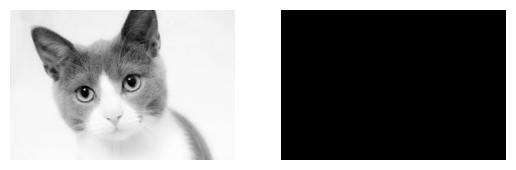

In [31]:
plt.subplot(1,2,1); plt.imshow(f, cmap="gray"); plt.axis("off")
plt.subplot(1,2,2); plt.imshow(g, cmap="gray"); plt.axis("off")